In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [2]:
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [3]:
Gam_quark = np.linspace(2.5,3.5,100)
n_quark = np.linspace(0.5344,2.3,1000)
p = 63.177
e = 318.26 + 253.89

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
m0_had = 939.56
K_had = 17906.60 

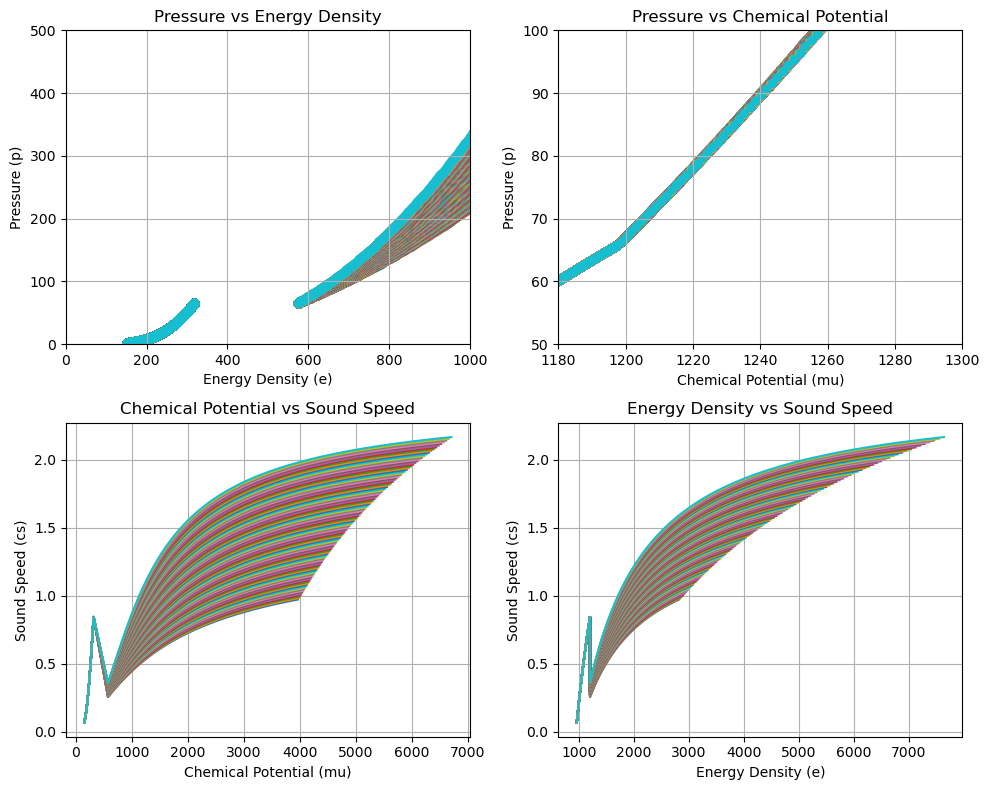

In [4]:
# Create a 2x2 grid of subplots outside the loop to include all curves in one plot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
# Initialize empty lists to store concatenated data
e_total, p_total, mu_total, cs_total, P_crit, mu_crit, n_total = [], [], [], [], [], [], []

# Loop through Gam_quark to plot curves for each value of g_quark
for g_quark in Gam_quark:

    # Hadronic EOS
    p_had = P_from_nb(n_had, K_had, Gam_had)
    mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)
    e_had = e_from_n(n_had, K_had, Gam_had, m0_had)
    cs_had = np.gradient(p_had, e_had)

    K_quark = p_had[-1] / (n_quark[0] ** g_quark)
    e_mid = n_quark[0]*mu_had[-1] - p_had[-1]
    m0_quark = (e_mid - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

    # Quark EOS
    p_quark = P_from_nb(n_quark, K_quark, g_quark)
    mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
    e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)
    cs_quark = np.gradient(p_quark, e_quark)

    # Concatenate hadronic and quark data
    e_combined = np.concatenate((e_had, e_quark))
    p_combined = np.concatenate((p_had, p_quark))
    mu_combined = np.concatenate((mu_had, mu_quark))
    cs_combined = np.concatenate((cs_had, cs_quark))
    n_combined = np.concatenate((n_had, n_quark))

    # Store concatenated data
    e_total.append(e_combined)
    p_total.append(p_combined)
    mu_total.append(mu_combined)
    cs_total.append(cs_combined)
    P_crit.append(p_quark[0])
    mu_crit.append(mu_quark[0])
    n_total.append(n_combined)

# After the loop, plot concatenated data
for i in range(len(Gam_quark)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].scatter(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 1].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 0].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].set_xlim(0,1000)
axes[0, 0].set_ylim(0,500)
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_xlim(1180,1300)
axes[0, 1].set_ylim(50,100)
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

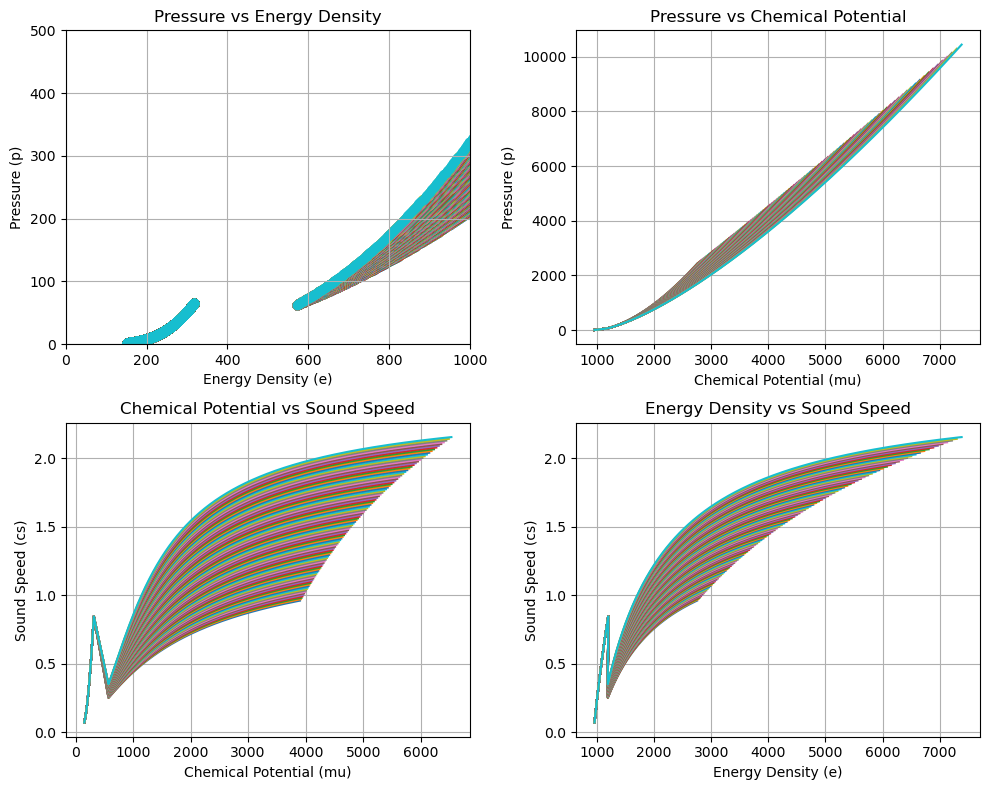

In [59]:
# Create a 2x2 grid of subplots outside the loop to include all curves in one plot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
# Initialize empty lists to store concatenated data
e_total, p_total, mu_total, cs_total, P_crit, mu_crit, n_total = [], [], [], [], [], [], []

# Loop through Gam_quark to plot curves for each value of g_quark
for g_quark in Gam_quark:
    K_quark = p / (n_quark[0] ** g_quark)
    m0_quark = (e - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

    # Hadronic EOS
    p_had = P_from_nb(n_had, K_had, Gam_had)
    mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)
    e_had = e_from_n(n_had, K_had, Gam_had, m0_had)
    cs_had = np.gradient(p_had, e_had)

    # Quark EOS
    p_quark = P_from_nb(n_quark, K_quark, g_quark)
    mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
    e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)
    cs_quark = np.gradient(p_quark, e_quark)

    # Concatenate hadronic and quark data
    e_combined = np.concatenate((e_had, e_quark))
    p_combined = np.concatenate((p_had, p_quark))
    mu_combined = np.concatenate((mu_had, mu_quark))
    cs_combined = np.concatenate((cs_had, cs_quark))
    n_combined = np.concatenate((n_had, n_quark))

    # Store concatenated data
    e_total.append(e_combined)
    p_total.append(p_combined)
    mu_total.append(mu_combined)
    cs_total.append(cs_combined)
    P_crit.append(p_quark[0])
    mu_crit.append(mu_quark[0])
    n_total.append(n_combined)

# After the loop, plot concatenated data
for i in range(len(Gam_quark)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 1].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 0].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].set_xlim(0,1000)
axes[0, 0].set_ylim(0,500)
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [5]:
P_crit_1 = P_crit[0]*(1+0.01)
P_crit_2 = P_crit[0]*(1+0.3)
P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

In [6]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []
a_optimal_1 = []
b_optimal_1 = []

# Iterate through each mu_total and p_total index
for index in range(len(mu_total)):

    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for P in P_crit_new:
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[0], P  # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)

    # Find the index of the minimum distance across all runs
    index = min_distances.argmin()

    # Save a specific optimal value to P_all based on index
    P_all.append(P_optimal[index])
    P_all_1.append(P_optimal[0])
    P_max_points.append(min_distance_points[index])
    P_max_points_1.append(min_distance_points[0])
    a_optimal_1.append(a_optimal)
    b_optimal_1.append(b_optimal)

In [7]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x > value), None)

def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

def compute_n_e(P, mu):
    """Compute number density (n_quad) and energy density (e_quad) from pressure (P) and chemical potential (mu)."""
    n_quad = gradient(P, mu)
    e_quad = (n_quad * mu[:-1]) - P[:-1]
    cs_quad = gradient(P[:-1],e_quad)
    return n_quad, e_quad, cs_quad


from TOV_Solver import generate_mr_curve
from EOS_construction import constructing_EOS

In [8]:
import numpy as np

def concatenate_eos(P_max_points_1,mu_crit,P_all_1,p_total,mu_total,a_optimal_1,b_optimal_1,e_total,n_total):
    eos_final = []
    for i in range(len(mu_crit)):

        x2, y2 = mu_crit[i], P_all_1[i]  # Critical point
        a_op = a_optimal_1[i][0]
        b_op = b_optimal_1[i][0]        
        # Define quadratic function
        def quadratic(x):
            return a_op * (x - x2)**2 + b_op * (x - x2) + y2
        
        # Generate smooth quadratic fit until quark EOS
        index = find_first_larger_index(mu_total[i], P_max_points_1[i][0])
        mu_mixed = np.linspace(mu_total[i][0], mu_total[i][index], len(mu_total[i][:index]))
        p_fit = quadratic(mu_mixed)
        n_mix,e_mix,cs_mix = compute_n_e(p_fit, mu_mixed)
        
        e_t = np.concatenate((e_mix, e_total[i][index:]))
        cs_t = np.concatenate((cs_mix, cs_total[i][index:]))
        p_t = np.concatenate((p_fit, p_total[i][index:]))
        mu_t = np.concatenate((mu_mixed, mu_total[i][index:]))

        #n_mix,e_t,cs_t = compute_n_e(p_t, mu_t)
        eos_final.append((p_t, mu_t, e_t, cs_t))
    #print(index)
    #print(mu_mixed)
    #print(mu_total[i][index:])
    return eos_final

In [9]:
eos = concatenate_eos(P_max_points_1,mu_crit,P_all_1,p_total,mu_total,a_optimal_1,b_optimal_1,e_total,n_total)

In [ ]:
r2, m2, c2, l2 = [], [], [], []
r1, m1, c1, l1 = [], [], [], []

In [129]:
r2, m2, c2, l2 = generate_mr_curve(e_total[40], p_total[40])
r1, m1, c1, l1 = generate_mr_curve(eos[40][2], eos[40][0][:-1])

In [80]:
import numpy as np

# Initialize indices as None
i_c, i_c1 = None, None

# Iterate over the valid range
for i in range(len(e_total[0]) - 1):
    # Check if cs_total[40][i] > 1 and store the first occurrence
    if cs_total[40][i] > 1 and i_c is None:
        i_c = int(i*(1/25))
    
    # Check if cs_quad_list[i] > 1 and store the first occurrence
    elif eos[40][3][i] > 1 and i_c1 is None:
        i_c1 = int(i*(1/25))

    # Exit loop early if both indices are found
    if i_c is not None and i_c1 is not None:
        break

print(f"i_c = {i_c}, i_c1 = {i_c1}")

i_c = 58, i_c1 = 58


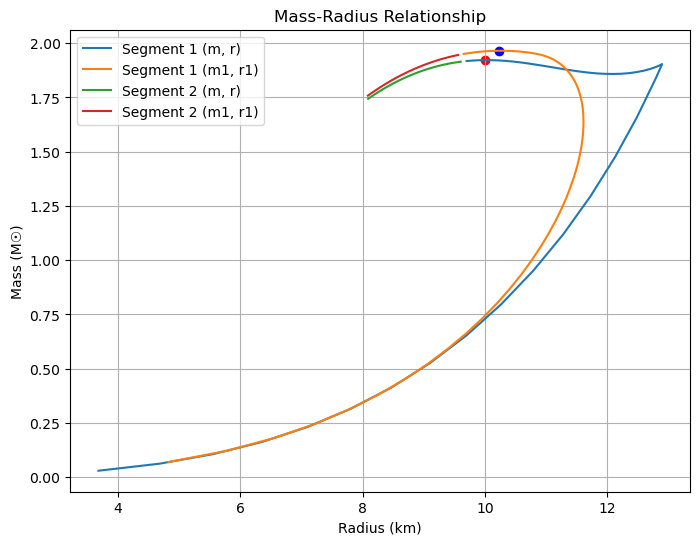

In [83]:
plt.figure(figsize=(8, 6))

# Plot the first and second segments for both sets
plt.plot(r[:i_c], m[:i_c], label="Segment 1 (m, r)")
plt.plot(r1[:i_c1], m1[:i_c1], label="Segment 1 (m1, r1)")
plt.plot(r[i_c:], m[i_c:], label="Segment 2 (m, r)")
plt.plot(r1[i_c1:], m1[i_c1:], label="Segment 2 (m1, r1)")
plt.scatter(r[np.argmax(m)], m[np.argmax(m)], color='red', marker='o')
plt.scatter(r1[np.argmax(m1)], m1[np.argmax(m1)], color='blue', marker='o')

# Labels and legend
plt.ylabel("Mass (M☉)")
plt.xlabel("Radius (km)")
plt.legend()
plt.title("Mass-Radius Relationship")
plt.grid(True)

plt.show()

In [25]:
from itertools import product
import numpy as np
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re

def find_valid_parameters(delta_P_arr, y_intersect, x_intersect, p_total, mu_total):
    A, B = [], []
    mu_c_h_arr, mu_c_q_arr = [], []
    P_c_h_arr, P_c_q_arr = [], []
    delta_P_found = []

    index = find_first_larger_index(p_total, y_intersect)
    #print(index)
    x1 = np.array(mu_total[:index])
    y1 = np.array(p_total[:index])

    x2 = np.array(mu_total[index:])
    y2 = np.array(p_total[index:])

    P_h_int_func = interpolate.interp1d(x1, y1, fill_value="extrapolate")
    P_q_int_func = interpolate.interp1d(x2, y2, fill_value="extrapolate")

    mu_new = np.linspace(1050, 1385, 1000)
    P_had_array = P_h_int_func(mu_new)
    P_quark_array = P_q_int_func(mu_new)
    #plt.plot(x1,y1)
    #plt.plot(x2,y2)
    #plt.show()
    #plt.plot(mu_new,P_had_array)
    #plt.plot(mu_new,P_quark_array)
    #plt.show()
    y_diff = np.abs(P_had_array - P_quark_array)

    for delta_P in delta_P_arr:
        found = False

        # Iterate through all combinations of mu_c_h and mu_c_q
        for mu_c_h, mu_c_q in product(mu_new, repeat=2):
            if found:
                break

            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            # Check if alpha is positive
            if alp <= 0:
                continue

            # Calculate the mixed phase pressure
            P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)

            # Split the pressure difference calculation
            min_idx = np.argmin(y_diff)
            m_h_P_diff = P_m[:min_idx] - P_had_array[:min_idx]
            m_q_P_diff = P_m[min_idx:] - P_quark_array[min_idx:]

            # Validate the pressure conditions
            if np.all(m_h_P_diff >= 0) and np.all(m_q_P_diff >= 0):
                #print(np.min(m_h_P_diff), np.min(m_q_P_diff))
                delta_P_found.append(delta_P)
                A.append(alp)
                B.append(bet)
                mu_c_h_arr.append(mu_c_h)
                mu_c_q_arr.append(mu_c_q)
                P_c_h_arr.append(P_h)
                P_c_q_arr.append(P_q)
                found = True

    print(f"Found {len(A)} valid sets of parameters.")
    return A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found

In [11]:
delta_P_arr = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10]

In [108]:
delta_P_arr = [0.01, 0.015, 0.02, 0.025, 0.03, 0.035, 0.04, 0.045, 0.05, 0.055, 0.06]

In [110]:
A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found = find_valid_parameters(delta_P_arr, P_crit[40], mu_crit[40], p_total[40], mu_total[40])

Found 9 valid sets of parameters.


In [111]:
def mixed_phase(mu_total, p_total,n_total, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit, P_crit):
    P_arr_dp = []
    E_arr_dp = []
    number_density_dp = []
    mu_arr_dp = []

    for i in range(len(A)):
        index_1 = find_first_larger_index(mu_total, mu_c_h_arr[i])
        index_2 = find_first_larger_index(mu_total, mu_c_q_arr[i])

        mu_mixed = np.linspace(mu_total[index_1], mu_total[index_2], len(mu_total[index_1:index_2]))

        P_m = quad_P(mu_crit, mu_mixed, A[i], B[i], delta_P_arr[i], P_crit)
        P_had_half = p_total[:index_1]
        P_quark_half = p_total[index_2:]

        grad_had = n_total[:index_1]
        grad_m = gradient(P_m,mu_mixed)
        grad_quark = n_total[index_2:]

        mu_arr = np.concatenate((mu_total[:index_1], mu_mixed[:-1], mu_total[index_2:]))

        grad_dummy = np.concatenate((grad_had,grad_m,grad_quark))
        P_arr_dummy = np.concatenate((P_had_half,P_m[:-1],P_quark_half))

        e_dummy = (grad_dummy*mu_arr)-P_arr_dummy

        P_arr_dp.append(P_arr_dummy)
        E_arr_dp.append(e_dummy)
        number_density_dp.append(grad_dummy)
        mu_arr_dp.append(mu_arr)

    return P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp

In [112]:
P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = mixed_phase(mu_total[40], p_total[40], n_total[40], A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit[40], P_crit[40])

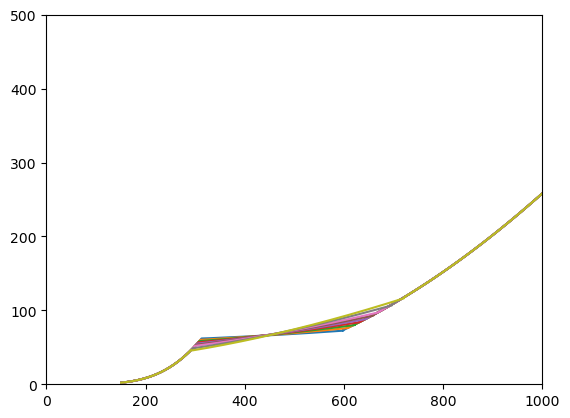

In [114]:
for i in range(9):
    plt.plot(E_arr_dp[i],P_arr_dp[i])
plt.xlim(0,1000)
plt.ylim(0,500)
plt.show()

In [115]:
radii, masses, compacts, love_nums = [0]*len(delta_P_arr), [0]*len(delta_P_arr), [0]*len(delta_P_arr), [0]*len(delta_P_arr)

In [116]:
for i in range(10):
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(E_arr_dp[i], P_arr_dp[i])

IndexError: list index out of range

NameError: name 'r1' is not defined

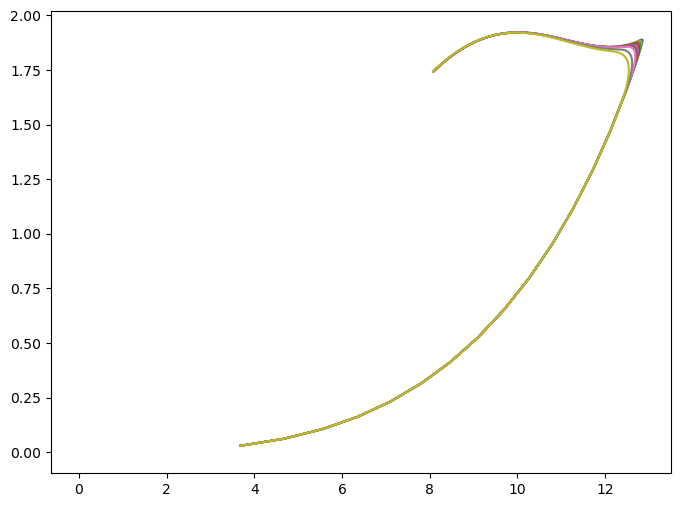

In [117]:
plt.figure(figsize=(8, 6))

for i in range(10):
    plt.plot(radii[i], masses[i])
plt.plot(r1, m1)
plt.plot(r2,m2)

# Labels and legend
plt.ylabel("Mass (M☉)")
plt.xlabel("Radius (km)")
plt.legend()
plt.title("Mass-Radius Relationship")
plt.grid(True)

plt.show()

In [118]:
def check_twins(mass):
    for i in range(len(mass)-2):
        if mass[i+1]-mass[i] < 0 and mass[i+2]-mass[i+1] > 0:
            return print('True')
    else:
        return print('False')

In [120]:
for i in range(len(masses)):
    check_twins(masses[i])
    print(delta_P_arr[i])

True
0.01
True
0.015
True
0.02
True
0.025
True
0.03
True
0.035
True
0.04
False
0.045
False
0.05


TypeError: object of type 'int' has no len()

In [ ]:
A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found = [0]*10, [0]*10, [0]*10, [0]*10, [0]*10, [0]*10, [0]*10

for i in range(10):
    j = (i*10)-1
    A[i], B[i], mu_c_h_arr[i], mu_c_q_arr[i], P_c_h_arr[i], P_c_q_arr[i], delta_P_found[i] = find_valid_parameters(delta_P_arr, P_crit[j], mu_crit[j], p_total[j], mu_total[j])

/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/scipy/interpolate/_interpolate.py:479: RuntimeWarning: invalid value encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]


In [32]:
for i in range(10):
    j = (i*10)-1
    P_arr_dp[i], E_arr_dp[i], number_density_dp[i], mu_arr_dp[i] = mixed_phase(mu_total[j], p_total[j], n_total[j], A[i], B[i], mu_c_h_arr[i], mu_c_q_arr[i], P_c_h_arr[i], P_c_q_arr[i], mu_crit[j], P_crit[j])
    print(i)

0
1
2
3
4
5
6
7
8
9


In [40]:
radii_1, masses_1, compacts_1, love_nums_1 = [], [], [], []
for i in range(10):
    radii, masses, compacts, love_nums = [0]*len(delta_P_found[i]), [0]*len(delta_P_found[i]), [0]*len(delta_P_found[i]), [0]*len(delta_P_found[i])
    for j in range(len(delta_P_found[i])):
        radii[j], masses[j], compacts[j], love_nums[j] = generate_mr_curve(E_arr_dp[i][j], P_arr_dp[i][j])
    radii_1.append(radii)
    masses_1.append(masses)
    compacts_1.append(compacts)
    love_nums_1.append(love_nums)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


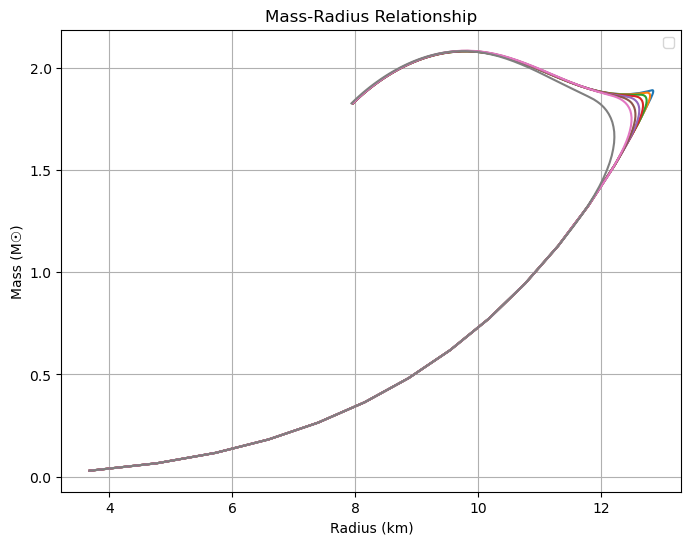

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


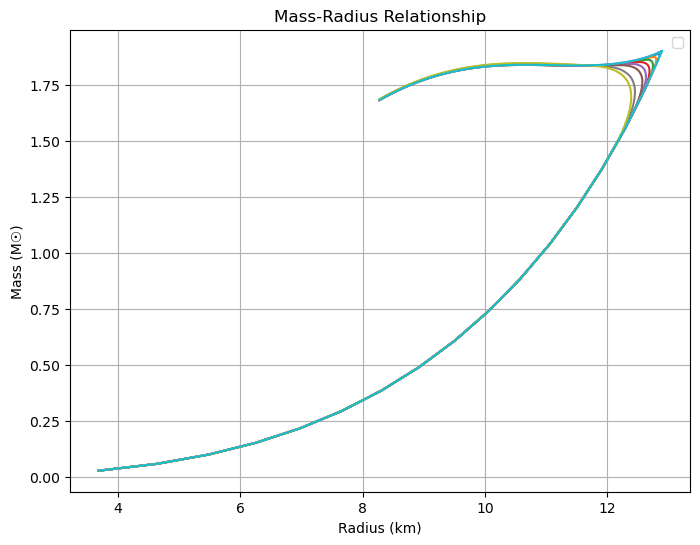

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


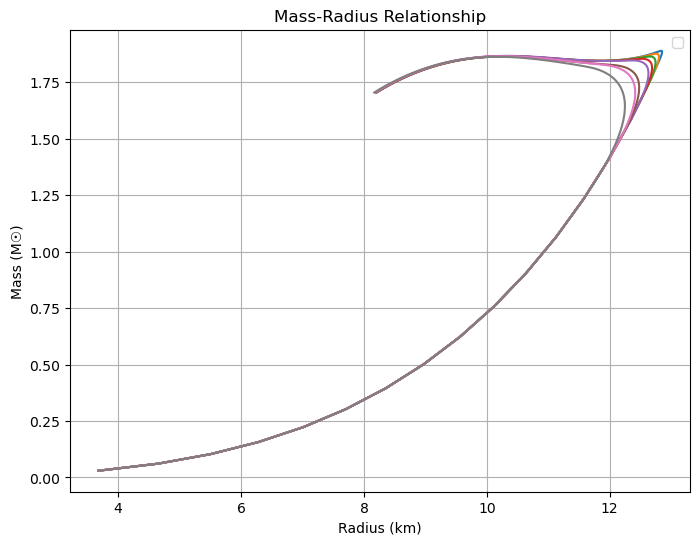

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


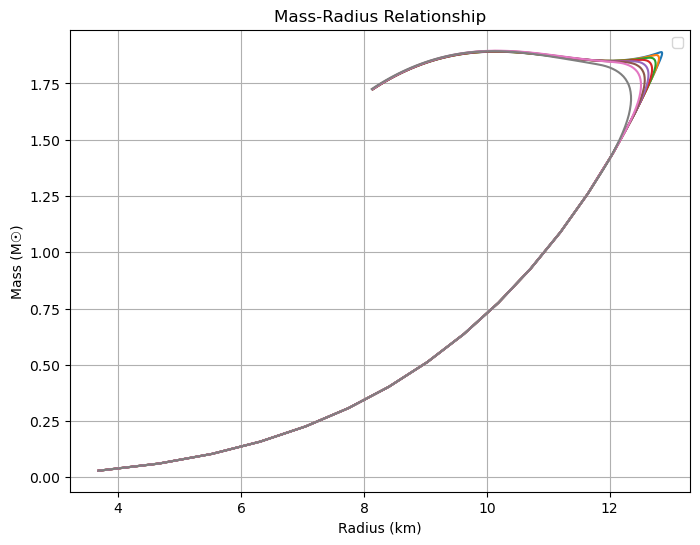

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


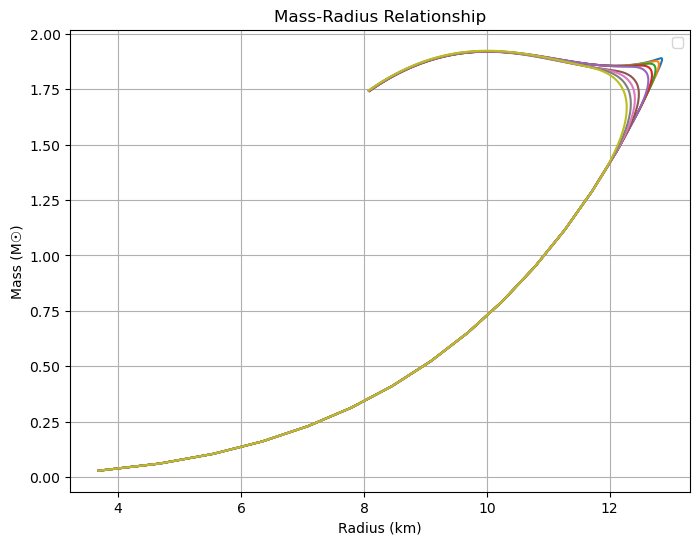

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


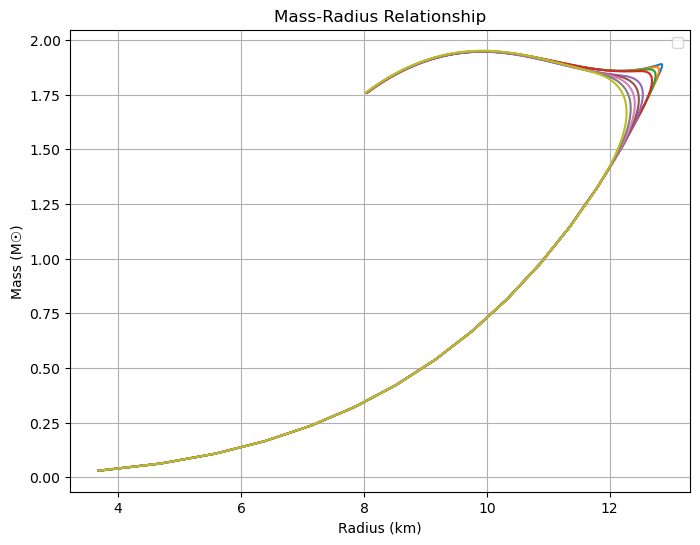

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


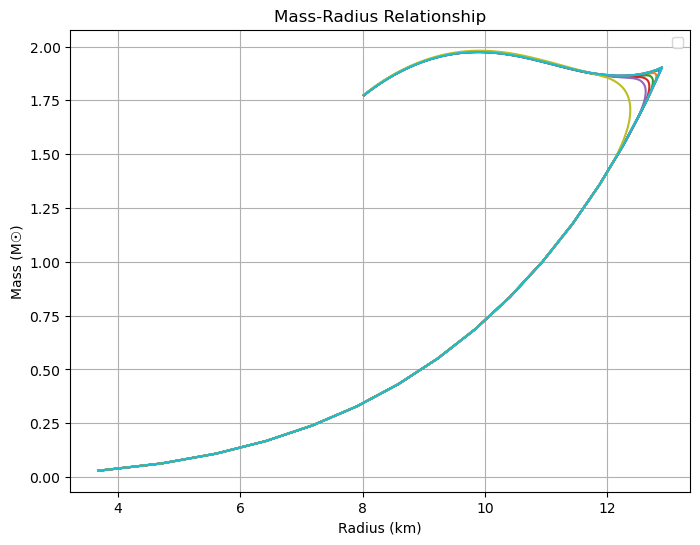

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


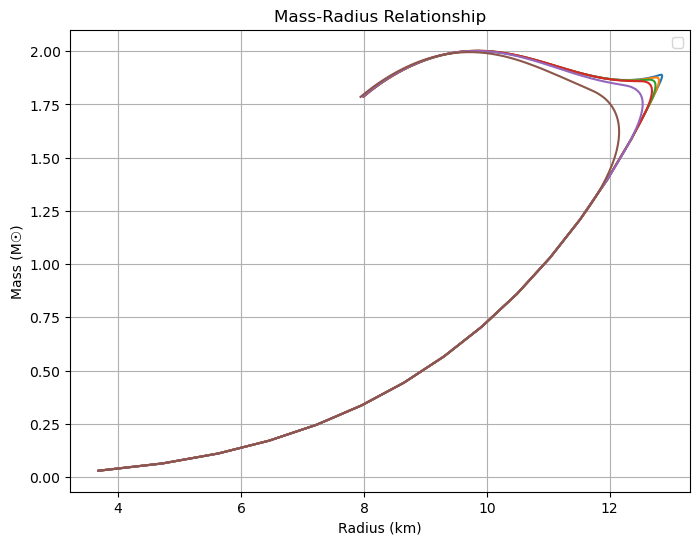

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


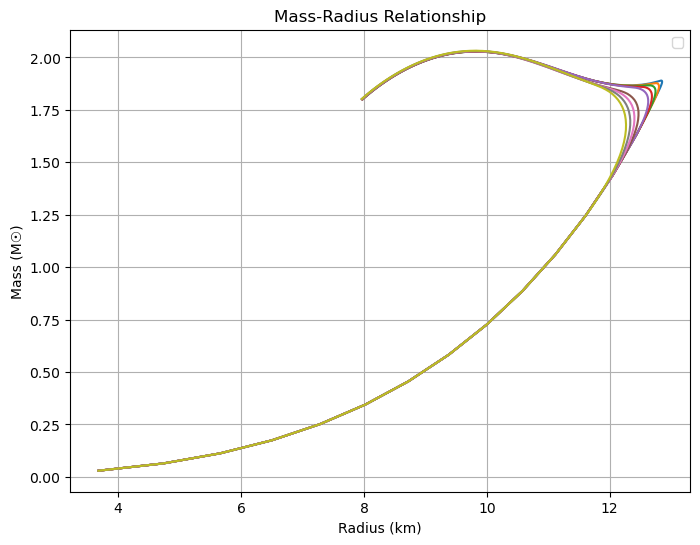

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


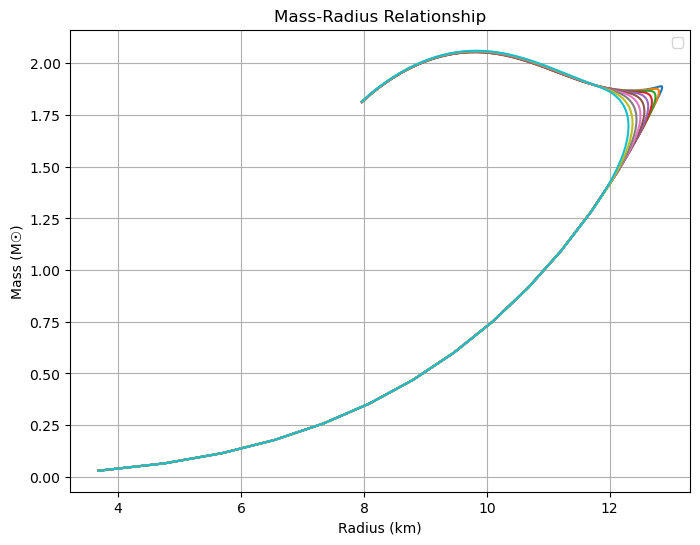

In [52]:
for j in range(10):
    plt.figure(figsize=(8, 6))

    for i in range(len(radii_1[j])):
        plt.plot(radii_1[j][i], masses_1[j][i])
    #plt.plot(r1, m1)
    #plt.plot(r2,m2)

    # Labels and legend
    plt.ylabel("Mass (M☉)")
    plt.xlabel("Radius (km)")
    plt.legend()
    plt.title("Mass-Radius Relationship")
    plt.grid(True)

    plt.show()

In [105]:
mu_crit

[1197.4073783618833,
 1197.4073783618833,
 1197.4073783618835,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618835,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618835,
 1197.4073783618835,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618835,
 1197.4073783618835,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618835,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618835,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618835,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783618833,
 1197.4073783

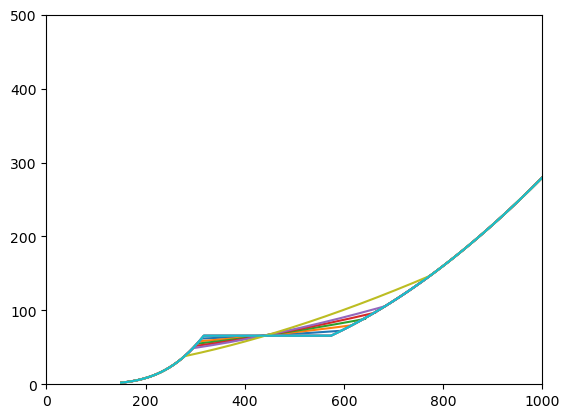

In [107]:
n = 6
for i in range(len(E_arr_dp[n])):
    plt.plot(E_arr_dp[n][i],P_arr_dp[n][i])
plt.xlim(0,1000)
plt.ylim(0,500)
plt.show()

In [82]:
gamma_p =[]
for i in range(10):
    j = (i*10)-1
    gamma_p.append(Gam_quark[j])

In [95]:
list = [0.03, 0.05, 0.05, 0.04, 0.04, 0.04, 0.04, 0.03, 0.03, 0.03]

In [86]:
gamma_p

[3.5,
 2.590909090909091,
 2.691919191919192,
 2.792929292929293,
 2.893939393939394,
 2.994949494949495,
 3.095959595959596,
 3.1969696969696972,
 3.297979797979798,
 3.3989898989898992]

Text(0, 0.5, '$\\Delta_p$')

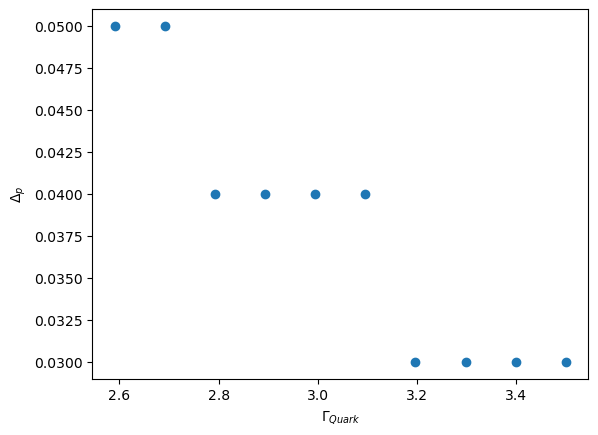

In [96]:
plt.scatter(gamma_p, list)
plt.xlabel(r"$\Gamma_{Quark}$")
plt.ylabel(r"$\Delta_p$")

In [94]:
n = 1
#plt.figure(figsize=(10, 8))
for i in range(len(masses_1[n])):
    check_twins(masses_1[n][i])
    print(delta_P_found[n][i])
    #plt.plot(radii_1[n][i], masses_1[n][i])
#plt.show()

True
0.01
True
0.02
True
0.03
True
0.04
True
0.05
True
0.06
True
0.07
False
0.08
False
0.09
True
0.1


In [31]:
P_arr_dp[1]

[array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.19160304e+00, ...,
        9.33413878e+03, 9.35857825e+03, 9.38306286e+03]),
 array([2.17013908e+00, 2.18085002e+00, 2.191603

In [ ]:
P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = [0]*10, [0]*10, [0]*10, [0]*10
radii, masses, compacts, love_nums = [0]*len(delta_P_arr), [0]*len(delta_P_arr), [0]*len(delta_P_arr), [0]*len(delta_P_arr)

In [ ]:
P_arr_dp[i], E_arr_dp[i], number_density_dp[i], mu_arr_dp[i] = mixed_phase(mu_total[j], p_total[j], n_total[j], A[i], B[i], mu_c_h_arr[i], mu_c_q_arr[i], P_c_h_arr[i], P_c_q_arr[i], mu_crit[j], P_crit[j])
radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(E_arr_dp[i], P_arr_dp[i])

i_c = None, i_c1 = None


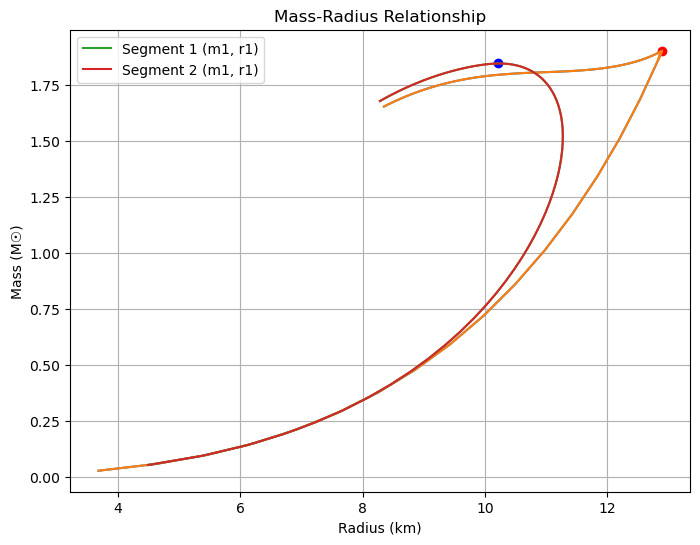

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_mass_radius(index):
    # Generate mass-radius curves
    r, m, c, l = generate_mr_curve(e_total[index], p_total[index])
    r1, m1, c1, l1 = generate_mr_curve(eos[index][2], eos[index][0])

    # Initialize indices as None
    i_c, i_c1 = None, None

    # Find the first index where cs_total or cs_quad_list exceeds 1
    for i in range(len(e_total[0]) - 1):
        if cs_total[index][i] > 1 and i_c is None:
            i_c = int(i*(1/25))
        if eos[index][3][i] > 1 and i_c1 is None:
            i_c1 = int(i*(1/25))

        # Exit loop early if both indices are found
        if i_c is not None and i_c1 is not None:
            break

    print(f"i_c = {i_c}, i_c1 = {i_c1}")

    # Create the plot
    plt.figure(figsize=(8, 6))

    # Plot the first and second segments for both sets
    plt.plot(r[:i_c], m[:i_c])  # First segment (m, r)
    plt.plot(r[i_c:], m[i_c:])  # Second segment (m, r)

    plt.plot(r1[:i_c1], m1[:i_c1], label="Segment 1 (m1, r1)")
    plt.plot(r1[i_c1:], m1[i_c1:], label="Segment 2 (m1, r1)")

    # Scatter points for maximum mass values
    plt.scatter(r[np.argmax(m)], m[np.argmax(m)], color='red', marker='o')
    plt.scatter(r1[np.argmax(m1)], m1[np.argmax(m1)], color='blue', marker='o')

    # Labels and legend
    plt.ylabel("Mass (M☉)")
    plt.xlabel("Radius (km)")
    plt.legend()
    plt.title("Mass-Radius Relationship")
    plt.grid(True)

    plt.show()

# Example usage
plot_mass_radius(0)

In [36]:
len(e_total)

100

i_c = None, i_c1 = None


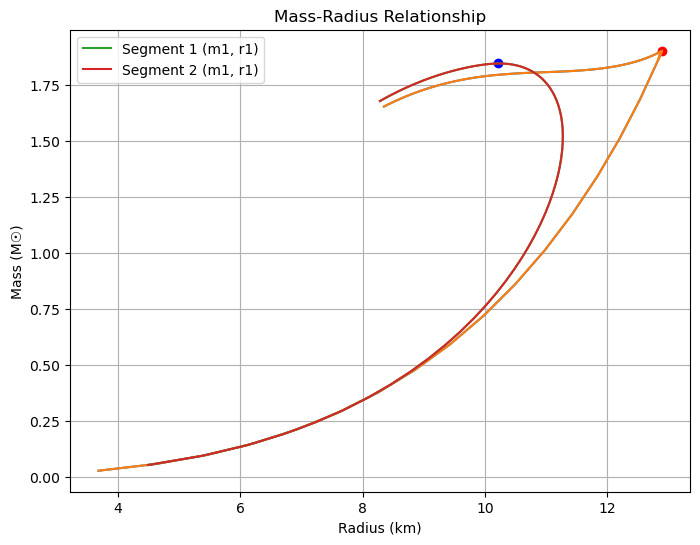

i_c = 1861, i_c1 = 1861


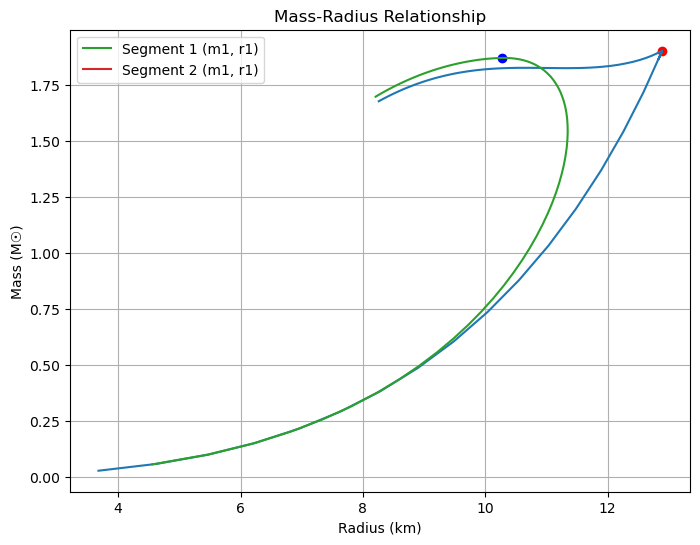

i_c = 1694, i_c1 = 1694


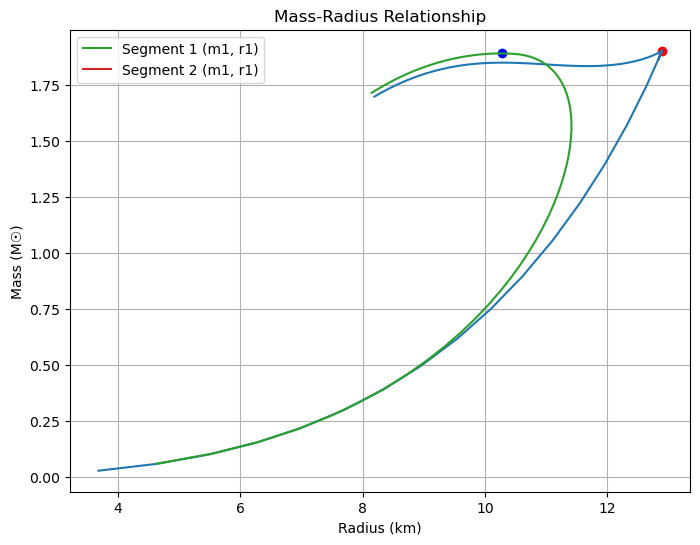

i_c = 1574, i_c1 = 1574


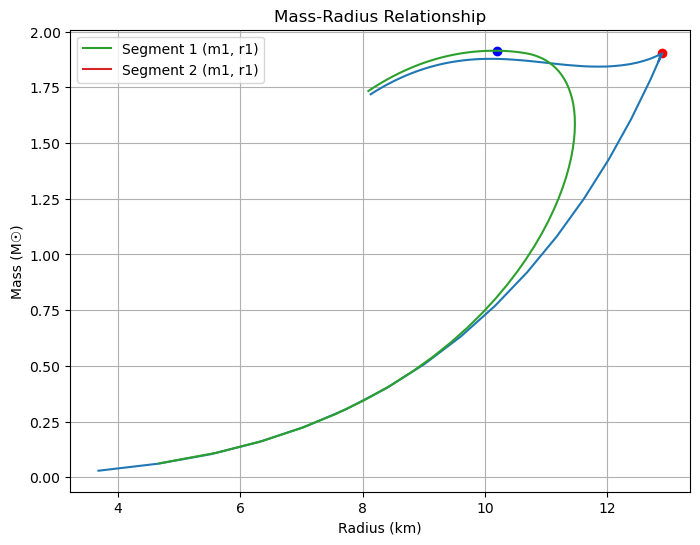

i_c = 1486, i_c1 = 1486


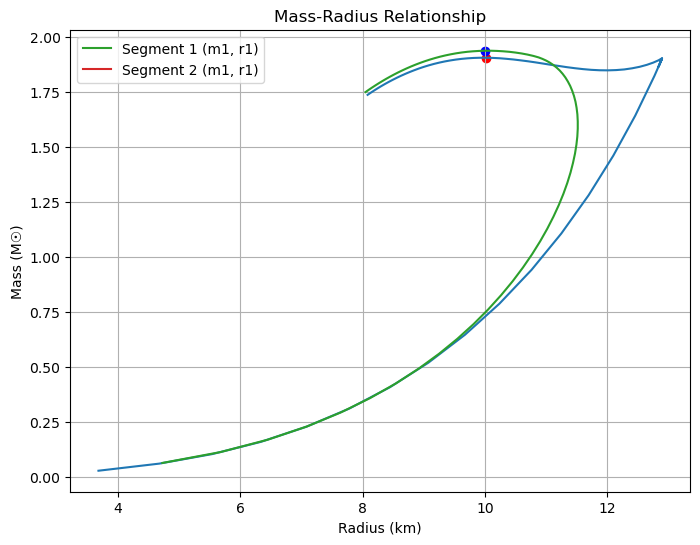

i_c = 1417, i_c1 = 1417


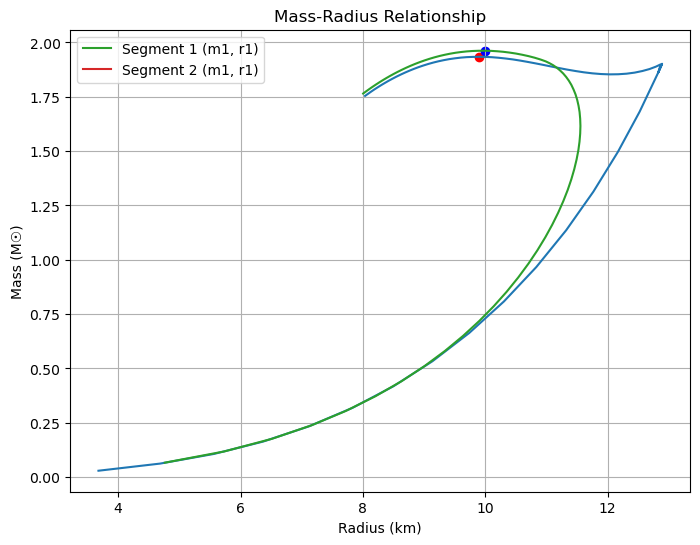

i_c = 1363, i_c1 = 1363


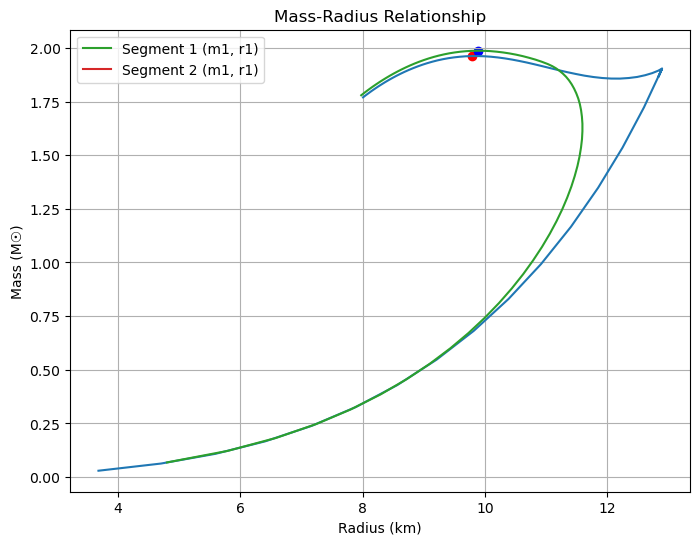

i_c = 1320, i_c1 = 1320


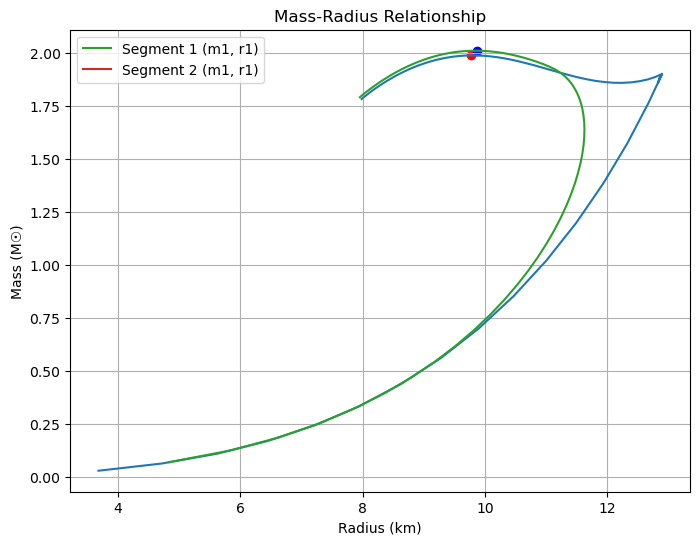

i_c = 1284, i_c1 = 1284


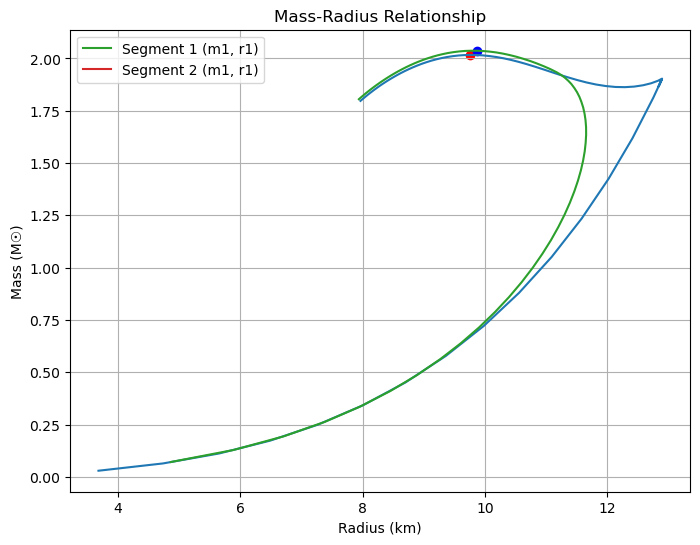

i_c = 1254, i_c1 = 1254


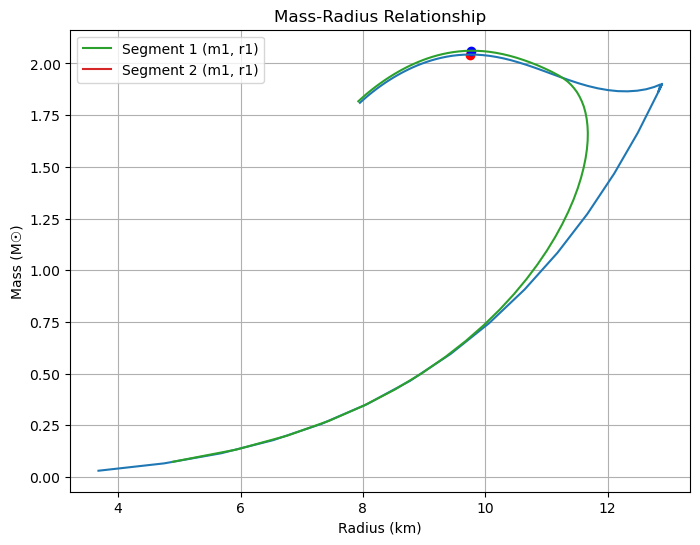

In [157]:
for i in range(10):
    navee = i*10
    plot_mass_radius(navee)
plt.show()

In [31]:
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re

In [30]:
from itertools import product
import numpy as np

def find_valid_parameters(delta_P_arr, mu_new, P_h_int_func, P_q_int_func, alpha, beta, quad_P, y_intersect, x_intersect, y_diff, P_had_array, P_quark_array):
    A, B = [], []
    mu_c_h_arr, mu_c_q_arr = [], []
    P_c_h_arr, P_c_q_arr = [], []

    for delta_P in delta_P_arr:
        found = False

        # Iterate through all combinations of mu_c_h and mu_c_q
        for mu_c_h, mu_c_q in product(mu_new, repeat=2):
            if found:
                break

            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            # Check if alpha is positive
            if alp <= 0:
                continue

            # Calculate the mixed phase pressure
            P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)

            # Split the pressure difference calculation
            min_idx = np.argmin(y_diff)
            m_h_P_diff = P_m[:min_idx] - P_had_array[:min_idx]
            m_q_P_diff = P_m[min_idx:] - P_quark_array[min_idx:]

            # Validate the pressure conditions
            if np.all(m_h_P_diff >= 0) and np.all(m_q_P_diff >= 0):
                print(np.min(m_h_P_diff), np.min(m_q_P_diff))

                A.append(alp)
                B.append(bet)
                mu_c_h_arr.append(mu_c_h)
                mu_c_q_arr.append(mu_c_q)
                P_c_h_arr.append(P_h)
                P_c_q_arr.append(P_q)
                found = True

    print(f"Found {len(A)} valid sets of parameters.")
    return A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr

In [ ]:
A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr = find_valid_parameters(delta_P_arr, mu_new, P_h_int_func, P_q_int_func, alpha, beta, quad_P, y_intersect, x_intersect, y_diff, P_had_array, P_quark_array)

In [71]:
radii_1, masses_1, compacts_1, love_nums_1 = [0]*len(list), [0]*len(list), [0]*len(list), [0]*len(list)

In [74]:
for i in range(len(list)):
    j = int(list[i])
    e_arr = e_total[j]
    p_arr = p_total[j]
    radii_1[i], masses_1[i], compacts_1[i], love_nums_1[i] = generate_mr_curve(e_arr, p_arr)

In [80]:
radii, masses, compacts, love_nums = [0]*len(list), [0]*len(list), [0]*len(list), [0]*len(list)

In [100]:
for i in range(len(list)):
    j = int(list[i])
    e_arr = e_quad_list[j]
    p_arr = p_total[j]
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(e_arr, p_arr)

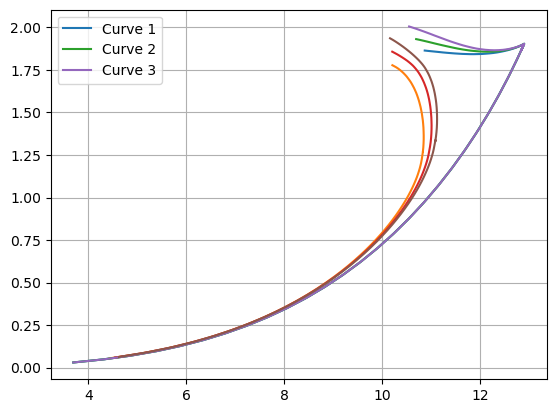

In [101]:
for i in range(len(list)):
    plt.plot(radii_1[i],masses_1[i], label=f"Curve {i+1}")
    plt.plot(radii[i],masses[i])
plt.grid()
plt.legend()

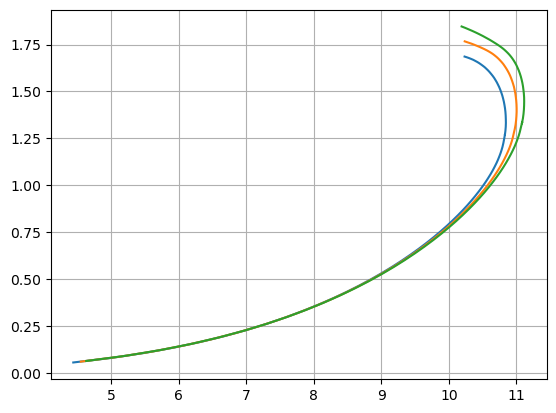

In [85]:
for i in range(len(list)):
    plt.plot(radii[i],masses[i])
plt.grid()

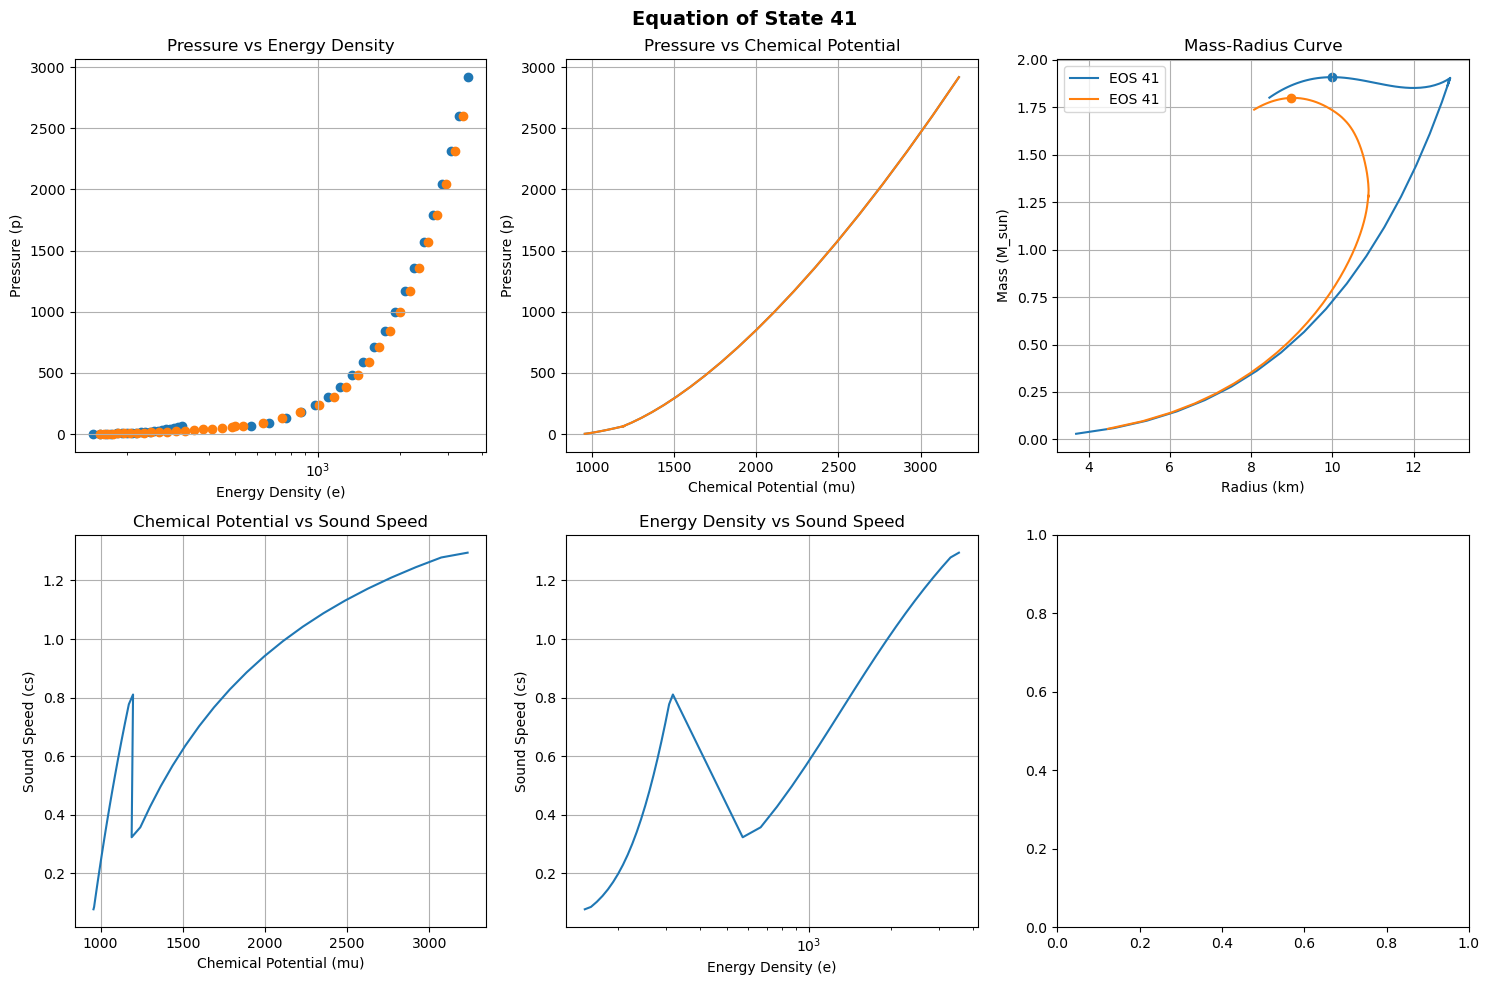

1.9075921162853524
1.7983222568296342


In [154]:
import matplotlib.pyplot as plt

def plot_eos(i, e_total, p_total, mu_total, cs_total, radii_1, masses_1):
    """
    Plots various properties of the Equation of State (EOS) for a given index.

    Parameters:
    - i: int, index of the EOS to plot
    - e_total: list of energy density values for different EOSs
    - p_total: list of pressure values for different EOSs
    - mu_total: list of chemical potential values for different EOSs
    - cs_total: list of sound speed values for different EOSs
    - generate_mr_curve: function that generates mass-radius data for an EOS
    """

    # Create a 2x3 grid of subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i])
    axes[0, 0].scatter(e_quad_list[i], p_total[i][:-1])
    axes[0, 0].set_title('Pressure vs Energy Density')
    axes[0, 0].set_xlabel('Energy Density (e)')
    axes[0, 0].set_ylabel('Pressure (p)')
    axes[0, 0].set_xscale('log')
    axes[0, 0].grid(True)

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])
    axes[0, 1].plot(eos[i][1], p_total[i])
    axes[0, 1].set_title('Pressure vs Chemical Potential')
    axes[0, 1].set_xlabel('Chemical Potential (mu)')
    axes[0, 1].set_ylabel('Pressure (p)')
    axes[0, 1].grid(True)

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])
    axes[1, 0].set_title('Chemical Potential vs Sound Speed')
    axes[1, 0].set_ylabel('Sound Speed (cs)')
    axes[1, 0].set_xlabel('Chemical Potential (mu)')
    axes[1, 0].grid(True)

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])
    axes[1, 1].set_title('Energy Density vs Sound Speed')
    axes[1, 1].set_ylabel('Sound Speed (cs)')
    axes[1, 1].set_xlabel('Energy Density (e)')
    axes[1, 1].set_xscale('log')
    axes[1, 1].grid(True)

    # Plot 5: Mass-Radius (M-R) Curve
    radii_111, masses_111, _, _ = generate_mr_curve(e_total[i], p_total[i])
    radii_112, masses_112, _, _ = generate_mr_curve(e_quad_list[i], p_total[i])
    axes[0, 2].plot(radii_111, masses_111, label=f'EOS {i+1}')
    axes[0, 2].scatter(radii_111[np.argmax(masses_111)], masses_111[np.argmax(masses_111)])
    axes[0, 2].scatter(radii_112[np.argmax(masses_112)], masses_112[np.argmax(masses_112)])
    axes[0, 2].plot(radii_112, masses_112, label=f'EOS {i+1}')
    axes[0, 2].set_title('Mass-Radius Curve')
    axes[0, 2].set_xlabel('Radius (km)')
    axes[0, 2].set_ylabel('Mass (M_sun)')
    axes[0, 2].legend()
    axes[0, 2].grid(True)

    # Adjust layout and show the plot
    plt.suptitle(f'Equation of State {i+1}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    print(max(masses_111))
    print(max(masses_112))

plot_eos(i=40, e_total=e_total, p_total=p_total, mu_total=mu_total, cs_total=cs_total, radii_1=radii_1, masses_1=masses_1)

In [153]:
max(masses_111)

NameError: name 'masses_111' is not defined

In [128]:
p_total[90]

array([  2.17013908,   2.79324934,   3.55125817,   4.4648113 ,
         5.55653146,   6.8511049 ,   8.37536764,  10.1583914 ,
        12.2315693 ,  14.62870119,  17.38607883,  20.54257074,
        24.13970687,  28.22176298,  32.83584485,  38.03197225,
        43.86316273,  50.38551513,  57.65829302,  65.74400784,
        63.177     ,  73.61053341,  85.20635597,  98.0369051 ,
       112.17587417, 127.69818238, 144.67994636, 163.19845362,
       183.3321374 , 205.16055305, 228.76435558, 254.22527839,
       281.62611316, 311.05069058, 342.58386216, 376.31148269,
       412.32039365, 450.69840728, 491.53429124, 534.91775407])

In [125]:
p_total[60]==eos[60][0]

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True,  True,
        True,  True,  True,  True])

In [105]:
len(radii_1)

3

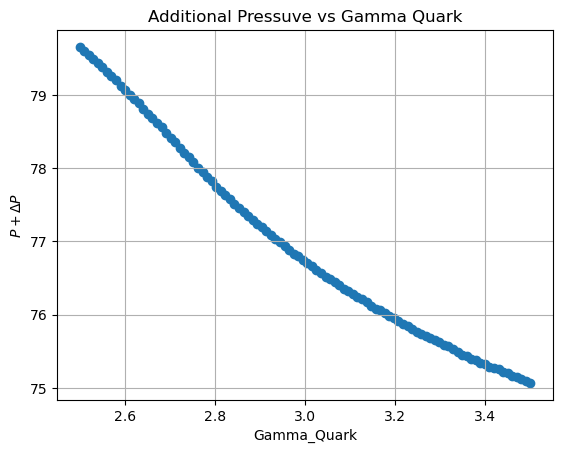

In [19]:
plt.scatter(Gam_quark,P_all_1);
plt.title("Additional Pressuve vs Gamma Quark")
plt.grid();
plt.xlabel('Gamma_Quark');
plt.ylabel(r'$P + \Delta P $');
plt.show();

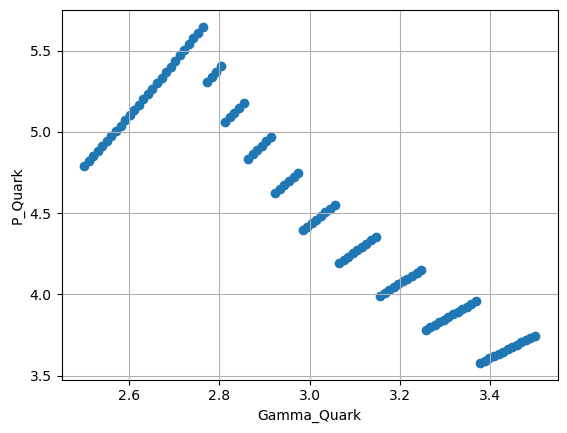

In [22]:
plt.scatter(Gam_quark,[y for x,y in P_max_points_1]/P_crit[0]);
plt.grid();
plt.xlabel('Gamma_Quark');
plt.ylabel(r'P_Quark');
plt.show();

In [21]:
def quadratic_fit(x, y):
    """
    Fit a quadratic curve to the given data points (x, y).

    Parameters:
        x (array-like): The input data points for the x-axis.
        y (array-like): The input data points for the y-axis.

    Returns:
        tuple: A tuple containing:
            - coefficients (a, b, c) for the quadratic curve y = ax^2 + bx + c
            - a function to compute fitted y-values for any input x.
    """
    # Perform quadratic curve fitting
    coefficients = np.polyfit(x, y, deg=2)  # Returns [a, b, c] for y = ax^2 + bx + c
    
    # Create a function for the fitted curve
    def fitted_curve(x_values):
        return coefficients[0] * x_values**2 + coefficients[1] * x_values + coefficients[2]
    
    return coefficients, fitted_curve

Quadratic Coefficients (a, b, c): [  2.71768221 -20.9600586  115.16462266]


<>:21: SyntaxWarning: invalid escape sequence '\G'
<>:21: SyntaxWarning: invalid escape sequence '\G'
<>:21: SyntaxWarning: invalid escape sequence '\G'
<>:21: SyntaxWarning: invalid escape sequence '\G'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_14897/816275865.py:21: SyntaxWarning: invalid escape sequence '\G'
  plt.plot(Gam_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\Gamma^2 + {coeffs[1]:.2f}\Gamma + {coeffs[2]:.2f}$', zorder=2)
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_14897/816275865.py:21: SyntaxWarning: invalid escape sequence '\G'
  plt.plot(Gam_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\Gamma^2 + {coeffs[1]:.2f}\Gamma + {coeffs[2]:.2f}$', zorder=2)


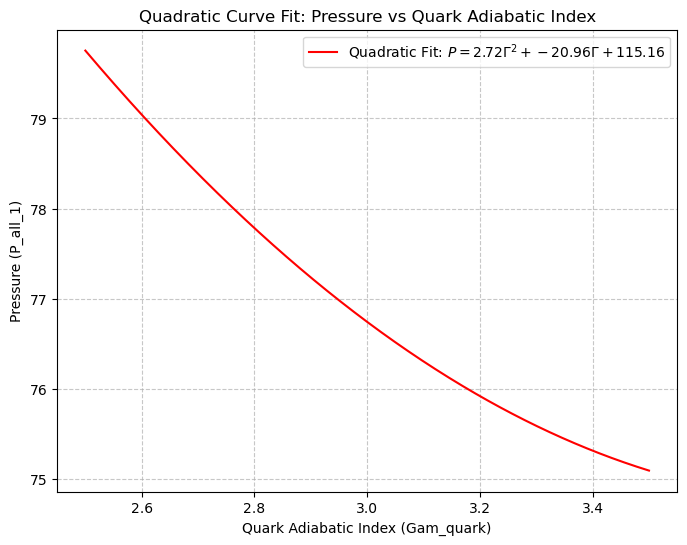

In [24]:
Gam_quark = np.array(Gam_quark)  # Replace with your actual data
P_all_1 = np.array(P_all_1)      # Replace with your actual data

# Check if their lengths match
if len(Gam_quark) != len(P_all_1):
    raise ValueError("Gam_quark and P_all_1 must have the same number of elements.")

# Get quadratic fit
coeffs, fit_fn = quadratic_fit(Gam_quark, P_all_1)

# Print the coefficients
print("Quadratic Coefficients (a, b, c):", coeffs)

# Generate fine-grained points for the fitted curve
Gam_fine = np.linspace(min(Gam_quark), max(Gam_quark), 500)  # Fine-grained x values
P_fitted = fit_fn(Gam_fine)

# Plot the original data and the fitted curve
plt.figure(figsize=(8, 6))
#plt.scatter(Gam_quark, P_all_1, color='blue', label='Original Data', zorder=3)
plt.plot(Gam_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\Gamma^2 + {coeffs[1]:.2f}\Gamma + {coeffs[2]:.2f}$', zorder=2)
plt.xlabel('Quark Adiabatic Index (Gam_quark)')
plt.ylabel('Pressure (P_all_1)')
plt.title('Quadratic Curve Fit: Pressure vs Quark Adiabatic Index')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()